## **Lab 7: Missing Data Pt. 2, Multinomial Logistic Regression, KNN**
### Fiona St. Clair

AI Disclosure: Claude Sonnet AI was used to help adapt the code from the instructions, class slideshows, and class notebooks into this lab. The written responses are my own logical and reasoning. 
***

## Part 1: Missing Data and Imputation

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

warnings.filterwarnings("ignore") 

### 1. Stochastic regression imputation of sysBP

In [2]:
# Read in the framingham dataset
framingham = pd.read_csv("../../../data/framingham.csv")

# Randomly delete 80% of blood pressure data (same seed as the in-class notebook)
missing_framingham = framingham.copy()
missing_framingham.loc[missing_framingham.sample(frac=0.8, random_state=567).index, 'sysBP'] = np.nan

# Models 1-3 (full data, missing data, mean imputation)
model1 = smf.ols("totChol ~ age + cigsPerDay + sysBP + BMI", data=framingham).fit()
model2 = smf.ols("totChol ~ age + cigsPerDay + sysBP + BMI", data=missing_framingham).fit()

mean_framingham = missing_framingham.copy()
mean_sysBP = mean_framingham['sysBP'].mean(skipna=True)
mean_framingham['sysBP'] = mean_framingham['sysBP'].fillna(mean_sysBP)
model3 = smf.ols("totChol ~ age + cigsPerDay + sysBP + BMI", data=mean_framingham).fit()

def coef_table(model):
    """Coefficients and 95% CIs, without the intercept."""
    table = model.conf_int().drop("Intercept")
    table.columns = ["lower", "upper"]
    table["coef"] = model.params.drop("Intercept")
    return table

#### a. Changing the noise seed in Approach #4

In [3]:
# Approach #4 (regression imputation) wrapped in a function so we can change the noise seed
# Using the observed data, predict sysBP from age, cigsPerDay, and BMI
observed = missing_framingham[missing_framingham['sysBP'].notna()]
missing = missing_framingham[missing_framingham['sysBP'].isna()]

formula = "sysBP ~ age + cigsPerDay + BMI"
imputer_model = smf.ols(formula, data=observed).fit()

def impute_sysBP(imputer, noise_seed):
    """Copy of the missing data with sysBP imputed from `imputer` plus residual noise."""
    predicted = imputer.predict(missing)
    residual_std = np.std(imputer.resid)
    rng = np.random.default_rng(noise_seed)
    imputed_values = predicted + rng.normal(0, residual_std, size=len(predicted))
    out = missing_framingham.copy()
    out.loc[missing.index, 'sysBP'] = imputed_values
    return out

# Original noise seed (123) and a new noise seed (2024)
reg_framingham = impute_sysBP(imputer_model, 123)
model4 = smf.ols("totChol ~ age + cigsPerDay + sysBP + BMI", data=reg_framingham).fit()

reg_framingham_newseed = impute_sysBP(imputer_model, 2024)
model4_newseed = smf.ols("totChol ~ age + cigsPerDay + sysBP + BMI", data=reg_framingham_newseed).fit()

models = {"model1 (framingham)": model1, "model2 (missing_framingham)": model2,
          "model3 (mean imputation)": model3, "model4 (regression imputation, seed 123)": model4,
          "model4 (regression imputation, seed 2024)": model4_newseed}

comparison = pd.DataFrame({
    label: pd.concat([m.params, pd.Series({"R²": m.rsquared, "Rows used": m.nobs})])
    for label, m in models.items()
})
formatted = comparison.map("{:.4f}".format)
formatted.loc["Rows used"] = comparison.loc["Rows used"].map("{:,.0f}".format)
formatted

,model1 (framingham),model2 (missing_framingham),model3 (mean imputation),"model4 (regression imputation, seed 123)","model4 (regression imputation, seed 2024)"
Intercept,134.2330,117.2945,125.2827,144.1388,143.6259
age,1.1522,1.3827,1.3259,1.3396,1.3291
cigsPerDay,0.1115,0.1058,0.1121,0.1136,0.1135
sysBP,0.2207,0.1423,0.1685,0.0157,0.0268
BMI,0.5886,1.1139,0.8588,0.8940,0.8772
R²,0.0871,0.1042,0.0793,0.0780,0.0781
Rows used,"4,143",829,"4,143","4,143","4,143"


In [4]:
print("sysBP coefficient, seed 123 :", round(model4.params["sysBP"], 4), " 95% CI:", model4.conf_int().loc["sysBP"].round(4).tolist())
print("sysBP coefficient, seed 2024:", round(model4_newseed.params["sysBP"], 4), " 95% CI:", model4_newseed.conf_int().loc["sysBP"].round(4).tolist())
print("sysBP coefficient, full data:", round(model1.params["sysBP"], 4), " 95% CI:", model1.conf_int().loc["sysBP"].round(4).tolist())

sysBP coefficient, seed 123 : 0.0157  95% CI: [-0.052, 0.0835]
sysBP coefficient, seed 2024: 0.0268  95% CI: [-0.0414, 0.095]
sysBP coefficient, full data: 0.2207  95% CI: [0.1533, 0.288]


**1a - Does the value of coefficient estimate for the sysBP change? What is this telling us?**

**Yes. The sysBP coefficient moves from 0.0157 at seed 123 to 0.0268 at seed 2024, and its 95% CI changes from [-0.052, 0.084] to [-0.041, 0.095]. The only thing that changed is the random noise added to the imputed values, so this tells us that a single stochastic imputation carries its own random variability that the model's standard errors doesn't account for. The pattern is stable though... both runs are far below the full data estimate of 0.2207 and both CIs include 0, so the attenuation toward zero comes from the imputation model and not from the particular noise draw.**

#### b. Repeating Approach #4 with totChol as a predictor of sysBP

##### i. Second formula

In [5]:
formula  = "sysBP ~ age + cigsPerDay + BMI"
formula2 = "sysBP ~ age + cigsPerDay + BMI + totChol"

##### ii. Second imputer model (saved in a copy of the data so the previous output is kept)

In [6]:
# Imputer 2 is fit on the observed sysBP values, using totChol as an extra predictor
imputer_model2 = smf.ols(formula2, data=observed).fit()

# Note: totChol itself has some missing values, so rows without totChol cannot be predicted.
# Those rows stay NaN (and are dropped by smf.ols anyway because totChol is the outcome).
predicted2 = imputer_model2.predict(missing)
print("Rows we need to impute:", len(missing), "| rows we could predict with formula2:", predicted2.notna().sum())

# Add residual noise to preserve variance (same noise seed as the original Approach #4)
residual_std2 = np.std(imputer_model2.resid)
noise_seed = 123
rng = np.random.default_rng(noise_seed)
imputed_values2 = predicted2 + rng.normal(0, residual_std2, size=len(predicted2))

reg_target_framingham = missing_framingham.copy()
reg_target_framingham.loc[missing.index, 'sysBP'] = imputed_values2

model5 = smf.ols("totChol ~ age + cigsPerDay + sysBP + BMI", data=reg_target_framingham).fit()

print(f"Imputer 1 (no target)  R²: {imputer_model.rsquared:.4f}, residual SD: {np.std(imputer_model.resid):.2f}")
print(f"Imputer 2 (with target) R²: {imputer_model2.rsquared:.4f}, residual SD: {residual_std2:.2f}")
print(imputer_model2.params.round(4))

Rows we need to impute: 3392 | rows we could predict with formula2: 3314
Imputer 1 (no target)  R²: 0.2479, residual SD: 19.25
Imputer 2 (with target) R²: 0.2447, residual SD: 19.24
Intercept     41.1381
age            0.8013
cigsPerDay     0.0528
BMI            1.7687
totChol        0.0287
dtype: float64


##### iii. Compare all 5 models (table and plot)

In [7]:
models = {"model1 (framingham)": model1, "model2 (missing_framingham)": model2,
          "model3 (mean imputation)": model3, "model4 (regression imputation)": model4,
          "model5 (regression imputation with target)": model5}

comparison = pd.DataFrame({
    label: pd.concat([m.params, pd.Series({"R²": m.rsquared, "Rows used": m.nobs})])
    for label, m in models.items()
})

formatted = comparison.map("{:.4f}".format)
formatted.loc["Rows used"] = comparison.loc["Rows used"].map("{:,.0f}".format)
formatted

,model1 (framingham),model2 (missing_framingham),model3 (mean imputation),model4 (regression imputation),model5 (regression imputation with target)
Intercept,134.2330,117.2945,125.2827,144.1388,138.9053
age,1.1522,1.3827,1.3259,1.3396,1.2427
cigsPerDay,0.1115,0.1058,0.1121,0.1136,0.1076
sysBP,0.2207,0.1423,0.1685,0.0157,0.1290
BMI,0.5886,1.1139,0.8588,0.8940,0.6981
R²,0.0871,0.1042,0.0793,0.0780,0.0811
Rows used,"4,143",829,"4,143","4,143","4,143"


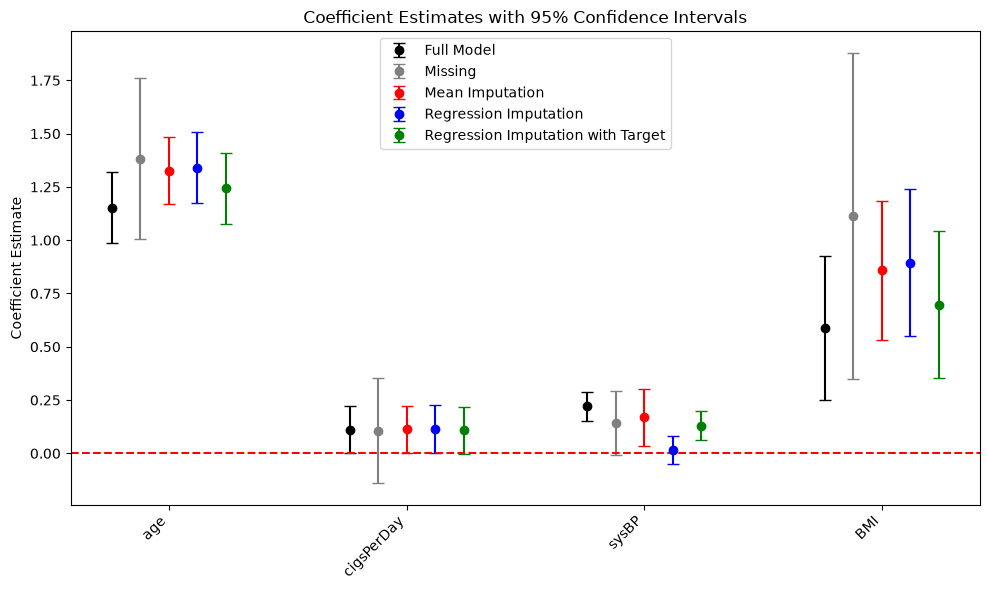

In [8]:
models = {
    "Full Model": (model1, "black"),
    "Missing": (model2, "gray"),
    "Mean Imputation": (model3, "red"),
    "Regression Imputation": (model4, "blue"),
    "Regression Imputation with Target": (model5, "green"),
}
tables = {name: coef_table(m) for name, (m, _) in models.items()}

common_vars = tables["Full Model"].index
for t in tables.values():
    common_vars = common_vars.intersection(t.index)

x = np.arange(len(common_vars))
width = 0.6/len(models)  # spacing between bars
offsets = (np.arange(len(models)) - (len(models) - 1) / 2) * width

plt.figure(figsize=(10, 6))
for offset, (name, (_, color)) in zip(offsets, models.items()):
    t = tables[name].loc[common_vars]
    plt.errorbar(
        x + offset, t["coef"],
        yerr=[t["coef"] - t["lower"], t["upper"] - t["coef"]],
        fmt='o', color=color, ecolor=color, capsize=4, label=name
    )

plt.axhline(0, color='red', linestyle='--')
plt.xticks(x, common_vars, rotation=45, ha='right')
plt.ylabel('Coefficient Estimate')
plt.title('Coefficient Estimates with 95% Confidence Intervals')
plt.legend()
plt.tight_layout()
plt.show()

#### c. Observations on imputing with the target variable

In [9]:
# sysBP coefficient (and CI) for each model, to make the comparison explicit
pd.DataFrame({name: {"coef": m.params["sysBP"], "lower": m.conf_int().loc["sysBP", 0],
                     "upper": m.conf_int().loc["sysBP", 1], "R²": m.rsquared, "Rows used": m.nobs}
              for name, (m, _) in models.items()}).T.round(4)

,coef,lower,upper,R²,Rows used
Full Model,0.2207,0.1533,0.2880,0.0871,4143.0
Missing,0.1423,-0.0095,0.2942,0.1042,829.0
Mean Imputation,0.1685,0.0336,0.3033,0.0793,4143.0
Regression Imputation,0.0157,-0.0520,0.0835,0.0780,4143.0
Regression Imputation with Target,0.1290,0.0614,0.1965,0.0811,4143.0


**1c - What do you observe about the imputation with the target variable? How is it different from the first regression imputation that did not include it?**

**With totChol in the imputer, the sysBP coefficient is 0.129 (95% CI 0.061 to 0.197). This is much closer to the full data estimate of 0.2207 (CI 0.153 to 0.288, and the intervals overlap) than the first regression imputation at 0.0157 (CI -0.052 to 0.084, which does not contain 0.22). The reason is that the first imputer fills in sysBP using only age, cigsPerDay, and BMI, so the imputed values contain no information about totChol beyond what those predictors carry, and the 80% imputed rows pull the sysBP to totChol relationship toward zero. Including totChol (imputer coefficient 0.029, positive) puts the sysBP to totChol relationship back into the imputed values. Using the outcome in the imputation model is not leakage here, but actually, it is what keeps the imputed values consistent with the analysis model. However, it still falls below the full data 0.22, the imputer itself is weak (R^2 of 0.245 vs 0.248, so totChol adds very little predictive power), and the rows that are missing totChol could not be imputed (they are dropped anyway). Overall, the model R squared barely moves (0.081 vs 0.078).**

***
## Part 2: Multinomial Logistic Regression

### Setup

In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import log_loss, accuracy_score, precision_score, recall_score, ConfusionMatrixDisplay

col_names= ["RI", "Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe", "type"]
glass = pd.read_csv("../../../data/glass.csv", header=None, names=col_names)

class_names = {1: "building_float", 2: "building_nonfloat", 3: "vehicle_float",
               5: "containers", 6: "tableware", 7: "headlamps"}
features = ["RI", "Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe"]

X = glass[features]
y = glass["type"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=113
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=224)

In [11]:
# Helper functions from the in-class notebook, extended to also report accuracy
def cv_scores(model):
    res = cross_validate(model, X_train, y_train, cv=cv, scoring=["neg_log_loss", "accuracy"])
    return {
        "log loss (mean)": -res["test_neg_log_loss"].mean(),
        "log loss (sd)": res["test_neg_log_loss"].std(),
        "accuracy (mean)": res["test_accuracy"].mean(),
        "accuracy (sd)": res["test_accuracy"].std(),
    }

def cv_pred(model):
    return cross_val_predict(model, X_train, y_train, cv=cv)

### 1. Data exploration and model baselines

#### a. Summary table of the features

In [12]:
print(glass.shape)
X.describe().T[["mean", "std", "min", "max"]].round(3)

(214, 10)


,mean,std,min,max
RI,1.518,0.003,1.511,1.534
Na,13.408,0.817,10.730,17.380
Mg,2.685,1.442,0.000,4.490
Al,1.445,0.499,0.290,3.500
Si,72.651,0.775,69.810,75.410
K,0.497,0.652,0.000,6.210
Ca,8.957,1.423,5.430,16.190
Ba,0.175,0.497,0.000,3.150
Fe,0.057,0.097,0.000,0.510


#### b. Class counts in the training and test sets

In [13]:
class_counts = pd.DataFrame({"train": y_train.value_counts().sort_index(),
                             "test": y_test.value_counts().sort_index()})
class_counts["total"] = class_counts.sum(axis=1)
class_counts.index = [f"{i}: {class_names[i]}" for i in class_counts.index]
class_counts

,train,test,total
1: building_float,56,14,70
2: building_nonfloat,61,15,76
3: vehicle_float,14,3,17
5: containers,10,3,13
6: tableware,7,2,9
7: headlamps,23,6,29


**1b - Which classes are rare? Which is the most common?**

**The rare classes are tableware (7 train, 2 test), containers (10 train, 3 test) and vehicle_float (14 train, 3 test). Headlamps (23 train) is moderate. The most common class is building_nonfloat (61 train, 15 test), followed closely by building_float (56 train, 14 test).**

#### c. Accuracy of always predicting the most common class

In [14]:
most_common = y_train.value_counts().idxmax()
acc_base = (y_train == most_common).mean()
print(f"Most common class in training set: {most_common} ({class_names[most_common]})")
print(f"Accuracy of always predicting it (training set): {acc_base:.4f}")

Most common class in training set: 2 (building_nonfloat)
Accuracy of always predicting it (training set): 0.3567


**1c - On the training set, what is the accuracy of a “model” that always predicts the most common class?**

**Always predicting the most common class (building_nonfloat) gives an accuracy of 0.3567 (61 of 171) on the training set.**

#### d. Base-rate log loss

In [15]:
# Baseline: predict the training class proportions for every fragment
class_props = y_train.value_counts(normalize=True).sort_index().values

ll_base = log_loss(y_train, np.tile(class_props, (len(y_train), 1)))
print(f"Base-rate log loss: {ll_base:.4f}")
print(f"ln(6): {np.log(6):.4f}")

Base-rate log loss: 1.5049
ln(6): 1.7918


**1d - Compute the base-rate log loss on the training set.**

**The base-rate log loss on the training set is 1.5049.**

#### e. Why is the base-rate log loss lower than ln 6?

**1e - Why is the base-rate log loss lower than ln 6?**

**ln 6 = 1.792 is the log loss when every class is given probability 1/6, which is only the right answer when the six classes are equally common. Here the classes are very unbalanced (building_nonfloat is about 36% of the training set and tableware only about 4%), so predicting the training proportions puts more probability on the classes that actually occur most often and less on the rare ones. The log loss of the class proportions is the entropy of the class distribution, which is always at most ln K and equals ln K only when the classes are perfectly balanced. So 1.505 is lower than 1.792 because of the imbalance.**

### 2. Build an unpenalized model (no regularization)

#### a. Do the oxide columns sum to 100?

In [16]:
oxides = [f for f in features if f != "RI"]
oxide_sum = glass[oxides].sum(axis=1)
print(oxide_sum.describe().round(3))
print("Fraction of rows with sum between 99 and 101:", ((oxide_sum > 99) & (oxide_sum < 101)).mean().round(3))

count    214.000
mean      99.874
std        0.122
min       99.020
25%       99.810
50%       99.890
75%       99.960
max      100.100
dtype: float64
Fraction of rows with sum between 99 and 101: 1.0


**2a - Observations**

**The oxide columns sum to between 99.02 and 100.10 in every row (mean 99.87, SD 0.12), so they essentially always sum to 100 (they are percentages of a whole composition, with only small rounding and unmeasured-trace differences). This means the eight oxide columns are almost perfectly linearly dependent, since knowing seven of them nearly determines the eighth. This is a built-in multicollinearity problem.**

#### b. Unpenalized multinomial logistic regression

In [17]:
def make_unpenalized():
    return Pipeline(steps=[
        ("scale", StandardScaler()),
        ("model", LogisticRegression(C=np.inf, max_iter=50000)),
    ])

model_unpen = make_unpenalized()
cv_unpen = cv_scores(model_unpen)
print({k: round(v, 4) for k, v in cv_unpen.items()})

model_unpen.fit(X_train, y_train)
coef_unpen = pd.DataFrame(model_unpen.named_steps["model"].coef_.T,
                          index=features, columns=[class_names[c] for c in model_unpen.classes_])
coef_unpen.round(2)

{'log loss (mean)': np.float64(4.2072), 'log loss (sd)': np.float64(1.0624), 'accuracy (mean)': np.float64(0.6262), 'accuracy (sd)': np.float64(0.0745)}


,building_float,building_nonfloat,vehicle_float,containers,tableware,headlamps
RI,-21.41,-20.16,-26.91,-20.57,44.95,44.10
Na,-37.22,-41.90,-30.65,-36.16,70.14,75.79
Mg,-12.09,-23.59,0.50,-17.83,19.06,33.95
Al,-20.55,-21.06,-16.08,-11.73,40.59,28.83
Si,-27.42,-32.29,-23.66,-24.21,44.12,63.46
K,4.16,0.57,6.94,3.29,-57.89,42.92
Ca,-2.91,-13.24,13.34,-2.48,-11.47,16.77
Ba,4.76,0.30,7.62,3.90,-53.14,36.56
Fe,21.04,21.28,20.65,20.83,-61.38,-22.42


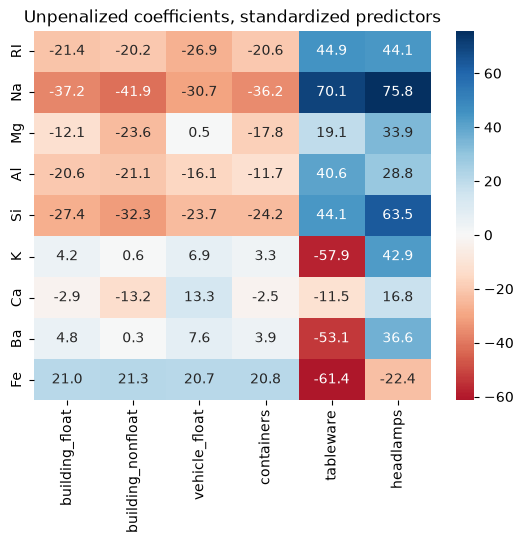

In [18]:
sns.heatmap(coef_unpen, annot=True, fmt=".1f", cmap="RdBu", center=0)
plt.title("Unpenalized coefficients, standardized predictors")
plt.show()

**2b - eport the mean log loss and accuracy, then fit the model on the full training set and look at its coefficients**

**The unpenalized model has a CV log loss of 4.2072 (SD 1.06) and a CV accuracy of 0.6262 (SD 0.075). The coefficients on the full training set are enormous for standardized predictors, mostly between about 10 and 75 in magnitude, with signs that jump around across classes (for example Na is about -37 for building_float but +76 for headlamps, and Fe is about +21 for four classes and -61 for tableware). These are not interpretable.**

#### c. VIF for each predictor

In [19]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

X_vif = add_constant(X_train)
vif = pd.Series([variance_inflation_factor(X_vif.values, i) for i in range(1, X_vif.shape[1])],
                index=features, name="VIF")
vif.round(2)

RI     11.53
Na     90.46
Mg    291.89
Al     33.85
Si     83.36
K      45.36
Ca    335.02
Ba     38.51
Fe      1.35
Name: VIF, dtype: float64

**2c - VIF for each of the nine predictors compared to part A and B**

**The VIFs are huge for most predictors: Ca 335, Mg 292, Na 90, Si 83, K 45, Ba 39, Al 34, RI 11.5, with only Fe low at 1.35 (a VIF above 5 to 10 is usually considered a problem). This matches Part a: because the oxides sum to about 100, they are nearly perfectly collinear with one another (and with RI, which depends on composition). With this much collinearity the model cannot separate the effect of one predictor from another, so the coefficients in Part b are very large, unstable and offsetting, and individual coefficients should not be interpreted. Predictions can still be reasonable (62.6% accuracy) because the combined effect is estimated, but the model is extremely sensitive to the training data.**

#### d. Unpenalized CV log loss vs. the base rate

In [20]:
print(f"Unpenalized CV log loss: {cv_unpen['log loss (mean)']:.4f}  (accuracy {cv_unpen['accuracy (mean)']:.4f})")
print(f"Base-rate log loss:      {ll_base:.4f}  (accuracy {acc_base:.4f})")

Unpenalized CV log loss: 4.2072  (accuracy 0.6262)
Base-rate log loss:      1.5049  (accuracy 0.3567)


**2d - How can a model with over 60% accuracy have a worse log loss than a model that uses no predictors at all?**

**The unpenalized model has a CV log loss of 4.21, much worse than the base-rate log loss of 1.50 even though its accuracy is 62.6% vs 35.7% for always guessing the most common class. Accuracy only asks whether the largest predicted probability lands on the right class, but log loss grades the probability itself. The huge coefficients push predicted probabilities toward 0 and 1, so the model is overconfident. When it is wrong (about 37% of the time), it can give the true class a probability close to 0, and log(p) for a tiny p is a very large penalty. A few of these confidently wrong predictions overwhelm the many mildly good ones. The base-rate model never gives any class a tiny probability, so it never gets hit with a huge penalty.**

### 3. Build a regularized multinomial logistic regression model

In [21]:
def make_model(C, l1_ratio):
    return Pipeline(steps=[
        ("scale", StandardScaler()),
        ("model", LogisticRegression(C=C, l1_ratio=l1_ratio, solver="saga", max_iter=50000, random_state=48)),
    ])

C_values = [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100, 300, 1000]
l1_ratios = {"lasso": 1, "enet 0.75": 0.75, "enet 0.5": 0.5, "enet 0.25": 0.25, "ridge": 0}

all_results = pd.DataFrame([{"model": name, "C": C, **cv_scores(make_model(C, r))}
                            for name, r in l1_ratios.items() for C in C_values])

In [22]:
# From all of the values of C that we tried above, select the simplest model within one standard error of the lowest log loss
best = all_results.loc[all_results["log loss (mean)"].idxmin()]
cutoff = best["log loss (mean)"] + best["log loss (sd)"] / np.sqrt(5)

candidates = all_results[all_results["log loss (mean)"] <= cutoff].copy()
candidates["l1_ratio"] = candidates["model"].map(l1_ratios)

# Fit each candidate on the full training set and count its nonzero coefficients
candidates["nonzero coefs (of 54)"] = [
    int((make_model(C, r).fit(X_train, y_train).named_steps["model"].coef_ != 0).sum())
    for C, r in zip(candidates["C"], candidates["l1_ratio"])
]
simplest = candidates.sort_values(["nonzero coefs (of 54)", "C"]).iloc[0]   # fewest nonzero, then smallest C

C_best, method_best, l1_best = simplest["C"], simplest["model"], simplest["l1_ratio"]
model_best = make_model(C_best, l1_best)

#### a. CV log loss vs. C

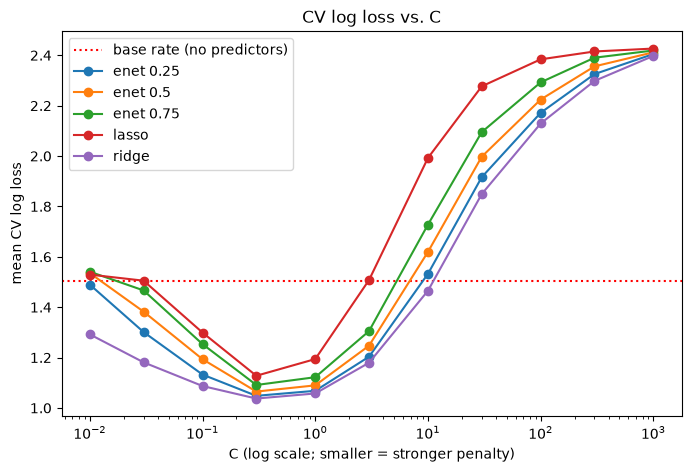

Lowest CV log loss: ridge, C = 0.3, log loss = 1.0374 (SE = 0.0698)
1-SE cutoff: 1.1072
Simplest within 1 SE: enet 0.75 (l1_ratio = 0.75), C = 0.3
Nonzero coefficients: 27 of 54
Selected model CV log loss = 1.0912, CV accuracy = 0.5854


,model,C,log loss (mean),log loss (sd),accuracy (mean),accuracy (sd),l1_ratio,nonzero coefs (of 54)
14,enet 0.75,0.3,1.0912,0.1711,0.5854,0.0575,0.75,27
25,enet 0.5,0.3,1.0650,0.1618,0.5620,0.0643,0.50,30
26,enet 0.5,1.0,1.0897,0.2688,0.6089,0.0653,0.50,43
36,enet 0.25,0.3,1.0482,0.1610,0.5854,0.0710,0.25,39
37,enet 0.25,1.0,1.0681,0.2469,0.6091,0.0825,0.25,49
46,ridge,0.1,1.0871,0.1113,0.5563,0.0715,0.00,54
47,ridge,0.3,1.0374,0.1561,0.5971,0.0627,0.00,54
48,ridge,1.0,1.0575,0.2466,0.6091,0.0825,0.00,54


In [23]:
fig, ax = plt.subplots(figsize=(8, 5))
for name, g in all_results.groupby("model"):
    ax.errorbar(g["C"], g["log loss (mean)"], marker="o", capsize=3, label=name)
ax.axhline(ll_base, color="red", ls=":", label="base rate (no predictors)")
ax.set(xscale="log", xlabel="C (log scale; smaller = stronger penalty)",
       ylabel="mean CV log loss", title="CV log loss vs. C")
ax.legend()
plt.show()

print(f"Lowest CV log loss: {best['model']}, C = {best['C']}, log loss = {best['log loss (mean)']:.4f} (SE = {best['log loss (sd)'] / np.sqrt(5):.4f})")
print(f"1-SE cutoff: {cutoff:.4f}")
print(f"Simplest within 1 SE: {method_best} (l1_ratio = {l1_best}), C = {C_best}")
print(f"Nonzero coefficients: {simplest['nonzero coefs (of 54)']} of 54")
print(f"Selected model CV log loss = {simplest['log loss (mean)']:.4f}, CV accuracy = {simplest['accuracy (mean)']:.4f}")
candidates.round(4)

**3a Which penalty and C give the lowest CV log loss? Which model does the one-standard-error rule select, and how many of its 54 coefficients are nonzero?**

**The lowest CV log loss is ridge with C = 0.3 (log loss 1.0374, SE about 0.070, so the cutoff is 1.1072). The one-standard-error rule selects the elastic net with l1_ratio = 0.75 at C = 0.3 (CV log loss 1.0912), and 27 of its 54 coefficients are nonzero (the ridge model has all 54). All of the penalized models near the minimum are clearly below the base rate of 1.505.**

#### b. CV accuracy vs. C

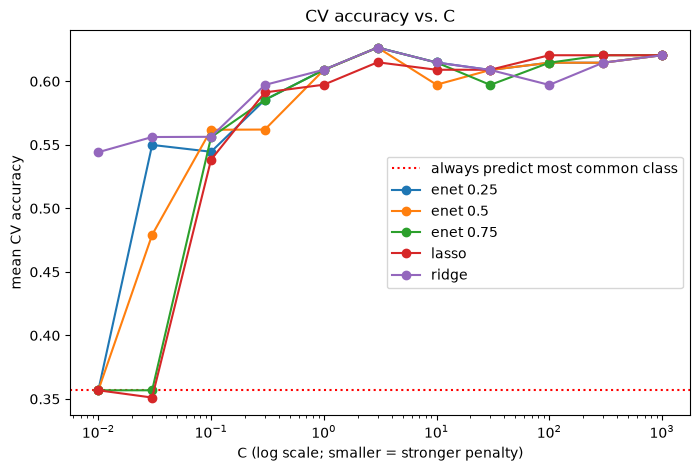

Highest CV accuracy: enet 0.75, C = 3.0, accuracy = 0.6266, log loss = 1.3052
Selected model: enet 0.75, C = 0.3, accuracy = 0.5854, log loss = 1.0912


,model,C,log loss (mean),log loss (sd),accuracy (mean),accuracy (sd)
16,enet 0.75,3.0,1.3052,0.5645,0.6266,0.0763
38,enet 0.25,3.0,1.2034,0.4529,0.6266,0.0763
27,enet 0.5,3.0,1.2472,0.5005,0.6266,0.0763
49,ridge,3.0,1.1795,0.4329,0.6266,0.0763
9,lasso,300.0,2.4151,1.6064,0.6205,0.0814
21,enet 0.75,1000.0,2.4190,1.6043,0.6205,0.0814
10,lasso,1000.0,2.4267,1.6073,0.6205,0.0814
32,enet 0.5,1000.0,2.4118,1.6016,0.6205,0.0814


In [24]:
fig, ax = plt.subplots(figsize=(8, 5))
for name, g in all_results.groupby("model"):
    ax.errorbar(g["C"], g["accuracy (mean)"], marker="o", capsize=3, label=name)
ax.axhline(acc_base, color="red", ls=":", label="always predict most common class")
ax.set(xscale="log", xlabel="C (log scale; smaller = stronger penalty)",
       ylabel="mean CV accuracy", title="CV accuracy vs. C")
ax.legend()
plt.show()

top_acc = all_results.loc[all_results["accuracy (mean)"].idxmax()]
print(f"Highest CV accuracy: {top_acc['model']}, C = {top_acc['C']}, accuracy = {top_acc['accuracy (mean)']:.4f}, log loss = {top_acc['log loss (mean)']:.4f}")
print(f"Selected model: {method_best}, C = {C_best}, accuracy = {simplest['accuracy (mean)']:.4f}, log loss = {simplest['log loss (mean)']:.4f}")
all_results.sort_values("accuracy (mean)", ascending=False).head(8).round(4)

**3b Which C has the highest accuracy? Compare with the log loss and accuracy of the model in part a.**

**The highest CV accuracy is 0.6266, reached at C = 3 by elastic net 0.75, 0.5, 0.25 and ridge (lasso peaks slightly lower at 0.6205 at large C). The selected model from 3a (enet 0.75, C = 0.3) has a CV accuracy of 0.5854 and a log loss of 1.0912, while the most accurate models (C = 3) have log losses of 1.18 to 1.31. So we give up about 4 percentage points of accuracy to get a log loss that is 0.1 to 0.2 lower. Accuracy differences of that size are smaller than the fold-to-fold SD (about 0.06 to 0.08), so they should not be over-interpreted.**

#### c. Why do the large-C log loss curves sit above the base rate?

In [25]:
print(all_results[all_results["C"] >= 10].groupby("model")[["log loss (mean)", "accuracy (mean)"]].mean().round(4))
print(f"Base-rate log loss: {ll_base:.4f}, base-rate accuracy: {acc_base:.4f}")

           log loss (mean)  accuracy (mean)
model                                      
enet 0.25           2.0702           0.6147
enet 0.5            2.1218           0.6112
enet 0.75           2.1850           0.6135
lasso               2.2990           0.6159
ridge               2.0279           0.6112
Base-rate log loss: 1.5049, base-rate accuracy: 0.3567


**3c - why is accuracy higher than the baseline for large C, but log loss gets worse?**

**A large C means a weak penalty, so the model approaches the unpenalized model from Q2: large coefficients, and predicted probabilities near 0 or 1. For C of at least 10 the average CV log loss is about 2.0 to 2.3, well above the base rate of 1.505 (and it approaches the 4.2 of the unpenalized model as C grows). Accuracy is still about 0.61 to 0.62, far above the 0.357 baseline, because accuracy only needs the correct class to have the highest probability. The weak penalty lets the model fit the training data, so its top choice is often right, but when it is wrong it is confidently wrong. Log loss punishes those confident errors heavily, which is exactly the situation described in 2d, so accuracy and log loss move in different directions.**

#### d. Coefficient heatmap of the selected model

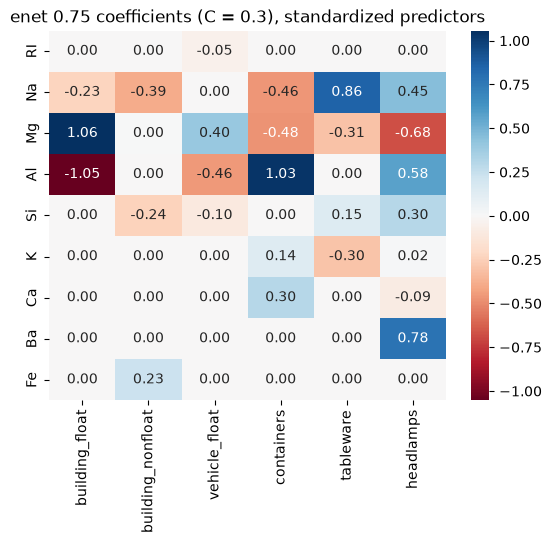

Number of classes with a nonzero coefficient, by feature:
RI    1
Na    5
Mg    6
Al    4
Si    4
K     3
Ca    2
Ba    1
Fe    1
dtype: int64
Features with a nonzero coefficient for only one class:
  RI: vehicle_float
  Ba: headlamps
  Fe: building_nonfloat


In [26]:
model_best.fit(X_train, y_train)
coef_table_best = pd.DataFrame(model_best.named_steps["model"].coef_.T,
                               index=features, columns=[class_names[c] for c in model_best.classes_])

sns.heatmap(coef_table_best, annot=True, fmt=".2f", cmap="RdBu", center=0)
plt.title(f"{method_best} coefficients (C = {C_best}), standardized predictors")
plt.show()

nonzero_per_feature = (coef_table_best != 0).sum(axis=1)
print("Number of classes with a nonzero coefficient, by feature:")
print(nonzero_per_feature)
print("Features with a nonzero coefficient for only one class:")
for f in nonzero_per_feature[nonzero_per_feature == 1].index:
    print(f"  {f}: {coef_table_best.columns[(coef_table_best.loc[f] != 0).values][0]}")

**3d - Which features have a nonzero coefficient for only one class?**

**Three features have a nonzero coefficient for only one class: RI (only vehicle_float), Ba (only headlamps) and Fe (only building_nonfloat). Mg is used by all six classes, and Na by five.**

#### e. Odds ratios for Ba and Mg

In [27]:
ba_factor = np.exp(coef_table_best.loc["Ba", "headlamps"] - coef_table_best.loc["Ba", "building_float"])
mg_factor = np.exp(coef_table_best.loc["Mg", "building_float"] - coef_table_best.loc["Mg", "headlamps"])
print(f"Ba: 1 SD increase multiplies odds of headlamps vs. building_float by exp({coef_table_best.loc['Ba', 'headlamps']:.3f} - ({coef_table_best.loc['Ba', 'building_float']:.3f})) = {ba_factor:.2f}")
print(f"Mg: 1 SD increase multiplies odds of building_float vs. headlamps by exp({coef_table_best.loc['Mg', 'building_float']:.3f} - ({coef_table_best.loc['Mg', 'headlamps']:.3f})) = {mg_factor:.2f}")

Ba: 1 SD increase multiplies odds of headlamps vs. building_float by exp(0.779 - (0.000)) = 2.18
Mg: 1 SD increase multiplies odds of building_float vs. headlamps by exp(1.057 - (-0.679)) = 5.67


**3e - By what factor does a one standard deviation increase in Ba multiply the odds of headlamps vs. building_float? Repeat for Mg, comparing building_float vs. headlamps.**

**a 1 SD increase multiplies the odds of headlamps vs building_float by exp(0.779 - 0) = 2.18, since the building_float coefficient for Ba is 0. Mg: a 1 SD increase multiplies the odds of building_float vs headlamps by exp(1.057 - (-0.679)) = exp(1.736) = 5.67.**

### 4. Where does the model make mistakes?

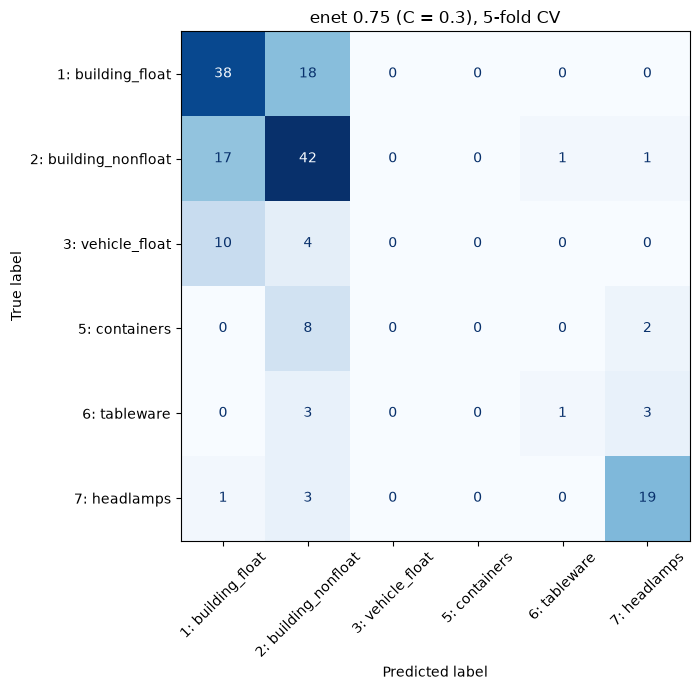

,precision,recall,n (train)
1: building_float,0.576,0.679,56
2: building_nonfloat,0.538,0.689,61
3: vehicle_float,0.000,0.000,14
5: containers,0.000,0.000,10
6: tableware,0.500,0.143,7
7: headlamps,0.760,0.826,23


In [28]:
pred_best = cv_pred(model_best)
labels = sorted(y_train.unique())
display_names = [f"{c}: {class_names[c]}" for c in labels]

fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(y_train, pred_best, labels=labels, display_labels=display_names,
                                        cmap="Blues", colorbar=False, ax=ax, xticks_rotation=45)
ax.set_title(f"{method_best} (C = {C_best}), 5-fold CV")
plt.tight_layout()
plt.show()

pr_table = pd.DataFrame({
    "precision": precision_score(y_train, pred_best, labels=labels, average=None, zero_division=0),
    "recall": recall_score(y_train, pred_best, labels=labels, average=None, zero_division=0),
    "n (train)": y_train.value_counts().sort_index().values,
}, index=display_names)
pr_table.round(3)

#### a. Which classes does the model almost never predict correctly?

**4a: vehicle_float (0 of 14 correct, precision and recall both 0) and containers (0 of 10, also 0) are never predicted correctly, and tableware is almost never correct (1 of 7, recall 0.143). These are the three rarest classes, and the model essentially never predicts vehicle_float or containers at all. The model does best on headlamps (recall 0.83, precision 0.76).**

#### b. Most vehicle_float fragments are predicted as which class?

In [29]:
pd.crosstab(pd.Series(y_train.values, name="actual").map(class_names),
            pd.Series(pred_best, name="predicted").map(class_names)).loc[["vehicle_float"]]

predicted,building_float,building_nonfloat,headlamps,tableware
actual,,,,
vehicle_float,10,4,0,0


**4b: 10 of the 14 vehicle_float fragments are predicted as building_float (the other 4 as building_nonfloat). The UCI description says that building_float and vehicle_float are both float glass, i.e. made by the same float process, and the only real difference is whether the window glass was used in a building or a vehicle. So they have essentially the same chemical composition, and the oxide and RI measurements cannot tell them apart. Vehicle_float also has only 14 training fragments compared with 56 for building_float.**

## Part 3: KNN + Model Comparisons

### 1. Choosing k and the distance metric

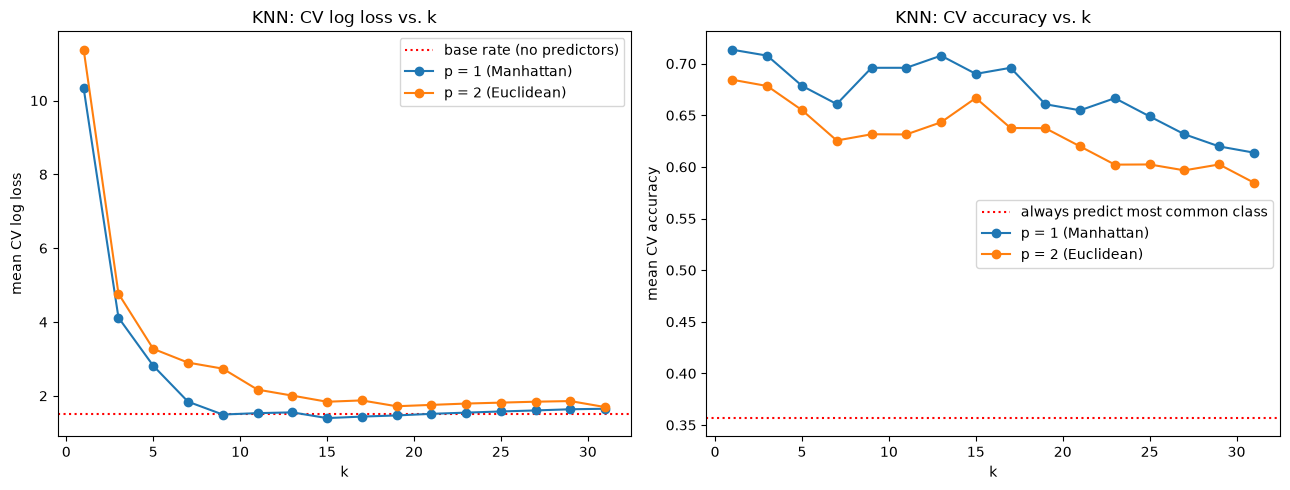

In [30]:
def make_knn(k, p):
    return Pipeline(steps=[
        ("scale", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=k, p=p)),
    ])

k_values = range(1, 32, 2)
knn_results = pd.DataFrame([{"k": k, "p": p, **cv_scores(make_knn(k, p))}
                            for p in [1, 2] for k in k_values])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for p, g in knn_results.groupby("p"):
    label = f"p = {p} ({'Manhattan' if p == 1 else 'Euclidean'})"
    axes[0].errorbar(g["k"], g["log loss (mean)"], marker="o", capsize=3, label=label)
    axes[1].errorbar(g["k"], g["accuracy (mean)"], marker="o", capsize=3, label=label)
axes[0].axhline(ll_base, color="red", ls=":", label="base rate (no predictors)")
axes[1].axhline(acc_base, color="red", ls=":", label="always predict most common class")
axes[0].set(xlabel="k", ylabel="mean CV log loss", title="KNN: CV log loss vs. k")
axes[1].set(xlabel="k", ylabel="mean CV accuracy", title="KNN: CV accuracy vs. k")
axes[0].legend(); axes[1].legend()
plt.tight_layout()
plt.show()

#### a. Which (k, p) gives the lowest CV log loss?

In [31]:
best_ll = knn_results.loc[knn_results["log loss (mean)"].idxmin()]
k_best, p_best = int(best_ll["k"]), int(best_ll["p"])
print(f"Lowest CV log loss: k = {k_best}, p = {p_best}, log loss = {best_ll['log loss (mean)']:.4f}, accuracy = {best_ll['accuracy (mean)']:.4f}")
knn_results.sort_values("log loss (mean)").head(5).round(4)

Lowest CV log loss: k = 15, p = 1, log loss = 1.3967, accuracy = 0.6901


,k,p,log loss (mean),log loss (sd),accuracy (mean),accuracy (sd)
7,15,1,1.3967,0.4744,0.6901,0.0437
8,17,1,1.4366,0.4685,0.6960,0.0601
9,19,1,1.4682,0.4771,0.6607,0.0583
4,9,1,1.4928,0.7274,0.6960,0.0629
10,21,1,1.5116,0.4785,0.6548,0.0804


**1a: The lowest CV log loss is k = 15 with p = 1 (Manhattan distance), log loss 1.3967 and accuracy 0.690.**

#### b. Choosing by accuracy instead

In [32]:
best_acc = knn_results.loc[knn_results["accuracy (mean)"].idxmax()]
print(f"Highest CV accuracy: k = {int(best_acc['k'])}, p = {int(best_acc['p'])}, accuracy = {best_acc['accuracy (mean)']:.4f}, log loss = {best_acc['log loss (mean)']:.4f}")
print(f"Worst CV log loss:   k = {int(knn_results.loc[knn_results['log loss (mean)'].idxmax(), 'k'])}, "
      f"p = {int(knn_results.loc[knn_results['log loss (mean)'].idxmax(), 'p'])}, log loss = {knn_results['log loss (mean)'].max():.4f}")
knn_results.sort_values("accuracy (mean)", ascending=False).head(6).round(4)

Highest CV accuracy: k = 1, p = 1, accuracy = 0.7134, log loss = 10.3285
Worst CV log loss:   k = 1, p = 2, log loss = 11.3765


,k,p,log loss (mean),log loss (sd),accuracy (mean),accuracy (sd)
0,1,1,10.3285,1.9404,0.7134,0.0538
6,13,1,1.5517,0.7257,0.7077,0.0517
1,3,1,4.1196,1.0725,0.7077,0.0826
5,11,1,1.5303,0.7222,0.6960,0.0682
8,17,1,1.4366,0.4685,0.6960,0.0601
4,9,1,1.4928,0.7274,0.6960,0.0629


**1b: Choosing by accuracy would give k = 1 with p = 1 (accuracy 0.7134, with k = 13 and p = 1 close behind at 0.7077). That k = 1 model has a CV log loss of 10.33 (and k = 1 with p = 2 has the worst log loss of all, 11.38). With k = 1 every predicted probability is exactly 0 or 1, so the model is right about 71% of the time but whenever it is wrong the true class gets probability 0, which sklearn clips to about 2.2e-16 and which costs about 36 for that fragment. The accuracy is good because many glass fragments have a near-duplicate nearest neighbor of the same type, but the model has no idea how uncertain it is. It would be a poor choice because its probabilities are useless, a single mistake dominates the loss, it is the most likely to be overfit, and its accuracy lead (0.713 vs 0.690) is much smaller than the fold-to-fold SD of about 0.05.**

In [33]:
model_knn = make_knn(k_best, p_best)

### 2. Where does KNN's log loss come from?

In [34]:
proba_knn = cross_val_predict(model_knn, X_train, y_train, cv=cv, method="predict_proba")
classes = np.sort(y_train.unique())
true_idx = np.searchsorted(classes, y_train.values)
p_true = proba_knn[np.arange(len(y_train)), true_idx]

# Pooled out-of-fold log loss (close to the fold-averaged value from cv_scores)
print("Pooled out-of-fold log loss:", round(log_loss(y_train, proba_knn), 4))

Pooled out-of-fold log loss: 1.3991


#### a. Fragments with probability 0 for the true class

In [35]:
zero_mask = p_true == 0
print("Number of fragments with probability exactly 0 for their true class:", zero_mask.sum())
pd.Series(y_train.values[zero_mask]).map(lambda c: f"{c}: {class_names[c]}").value_counts()

Number of fragments with probability exactly 0 for their true class: 3


7: headlamps     2
5: containers    1
Name: count, dtype: int64

**2a: 3 fragments have a predicted probability of exactly 0 for their true class: 2 are headlamps and 1 is containers.**

#### b. How much do they add to the log loss?

In [36]:
eps = np.finfo(float).eps
loss_each = -np.log(np.clip(p_true, eps, 1))          # per-fragment log loss
loss_zero_each = -np.log(eps)
total_ll = loss_each.mean()

print(f"-ln(eps) = {loss_zero_each:.2f} added by each zero-probability fragment to the sum of losses")
print(f"Each adds {loss_zero_each / len(y_train):.4f} to the mean log loss (n = {len(y_train)})")
print(f"Total contribution of the {zero_mask.sum()} fragments: {loss_each[zero_mask].sum() / len(y_train):.4f} of the {total_ll:.4f} total mean log loss")
print(f"Percentage of total KNN log loss from these fragments: {loss_each[zero_mask].sum() / loss_each.sum():.1%}")
print(f"Mean log loss of the remaining {(~zero_mask).sum()} fragments: {loss_each[~zero_mask].mean():.4f}")

-ln(eps) = 36.04 added by each zero-probability fragment to the sum of losses
Each adds 0.2108 to the mean log loss (n = 171)
Total contribution of the 3 fragments: 0.6323 of the 1.3991 total mean log loss
Percentage of total KNN log loss from these fragments: 45.2%
Mean log loss of the remaining 168 fragments: 0.7804


**2b: Each of these fragments contributes -ln(2.2e-16) = 36.04 to the sum of losses, which adds 36.04 / 171 = 0.211 to the mean log loss. Together the 3 fragments add 0.632 of the pooled 1.399 KNN log loss, which is 45.2 percent of it. The remaining 168 fragments have a mean log loss of 0.780, which is much better than the base rate of 1.505 and better than the logistic model's 1.09, so KNN is quite good on most fragments and its CV log loss is dominated by just 3 confidently wrong predictions.**

### 3. Comparing the two models

#### a. CV log loss, accuracy, and per-class recall

In [37]:
model_best_name = f"{method_best} (C = {C_best})"
model_knn_name = f"KNN (k = {k_best}, p = {p_best})"

summary = pd.DataFrame({
    model_best_name: cv_scores(model_best),
    model_knn_name: cv_scores(model_knn),
}).T
display(summary.round(4))

pred_knn = cv_pred(model_knn)
recall_table = pd.DataFrame({
    model_best_name: recall_score(y_train, pred_best, labels=labels, average=None),
    model_knn_name: recall_score(y_train, pred_knn, labels=labels, average=None),
    "n (train)": y_train.value_counts().sort_index().values,
}, index=display_names)
recall_table.round(3)

,log loss (mean),log loss (sd),accuracy (mean),accuracy (sd)
enet 0.75 (C = 0.3),1.0912,0.1711,0.5854,0.0575
"KNN (k = 15, p = 1)",1.3967,0.4744,0.6901,0.0437


,enet 0.75 (C = 0.3),"KNN (k = 15, p = 1)",n (train)
1: building_float,0.679,0.964,56
2: building_nonfloat,0.689,0.721,61
3: vehicle_float,0.000,0.000,14
5: containers,0.000,0.200,10
6: tableware,0.143,0.000,7
7: headlamps,0.826,0.783,23


**3a: Logistic regression has the lower CV log loss (1.0912 vs 1.3967), while KNN has the higher CV accuracy (0.690 vs 0.585). Per-class recall (logistic vs KNN): building_float 0.679 vs 0.964, building_nonfloat 0.689 vs 0.721, vehicle_float 0.000 vs 0.000, containers 0.000 vs 0.200, tableware 0.143 vs 0.000, headlamps 0.826 vs 0.783.**

#### b. Confusion matrices

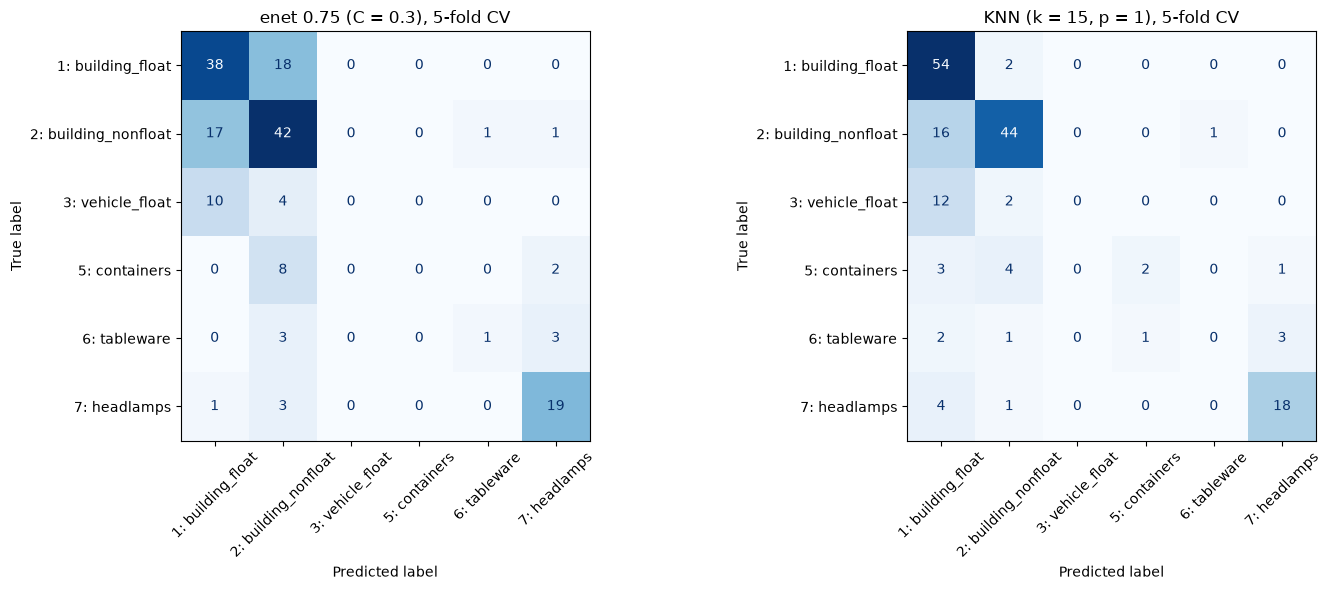

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (name, pred) in zip(axes, [(model_best_name, pred_best), (model_knn_name, pred_knn)]):
    ConfusionMatrixDisplay.from_predictions(y_train, pred, labels=labels, display_labels=display_names,
                                            cmap="Blues", colorbar=False, ax=ax, xticks_rotation=45)
    ax.set_title(f"{name}, 5-fold CV")
plt.tight_layout()
plt.show()

**3b: KNN gets 118 of 171 training fragments correct versus 100 for the logistic model, so 18 more correct. Of those, 16 are in building_float alone (54 of 56 correct vs 38 of 56), with 2 more for each of building_nonfloat and containers, and 1 fewer each for headlamps and tableware. So KNN's extra accuracy is mostly from classifying one large class (building_float) better, and it still gets no vehicle_float right (12 of its 14 go to building_float). It is not a good reason to prefer KNN because accuracy rewards getting the biggest classes right and ignores the rare classes, the gain is concentrated in one class, it is small relative to fold-to-fold variation, and the probabilities are worse (log loss 1.40 vs 1.09, with 45 percent of KNN's log loss from only 3 fragments with a probability of 0). If we care about probabilities (which is what log loss measures), the logistic model is better.**

#### c. Which classes does KNN handle better?

**3c: KNN handles building_float much better (recall 0.964 vs 0.679), building_nonfloat slightly better (0.721 vs 0.689) and containers a little better (0.20 vs 0.0, but only 2 of 10 fragments). It does not help for vehicle_float (0 for both models), tableware (0.0 vs 0.143, slightly worse) or headlamps (0.783 vs 0.826, slightly worse). This suggests that the boundary between building_float and building_nonfloat is not well described by a linear boundary and is more local or irregular, which KNN can follow and the logistic model cannot. The classes that neither model can find (vehicle_float vs building_float, and the tiny classes) are not separable in these features by either a linear or a flexible boundary, since they overlap with other classes, and with so few fragments neither method can learn them.**

### 4. Evaluate on the test set

,test log loss,test accuracy
enet 0.75 (C = 0.3),0.8864,0.6512
"KNN (k = 15, p = 1)",0.7538,0.6279


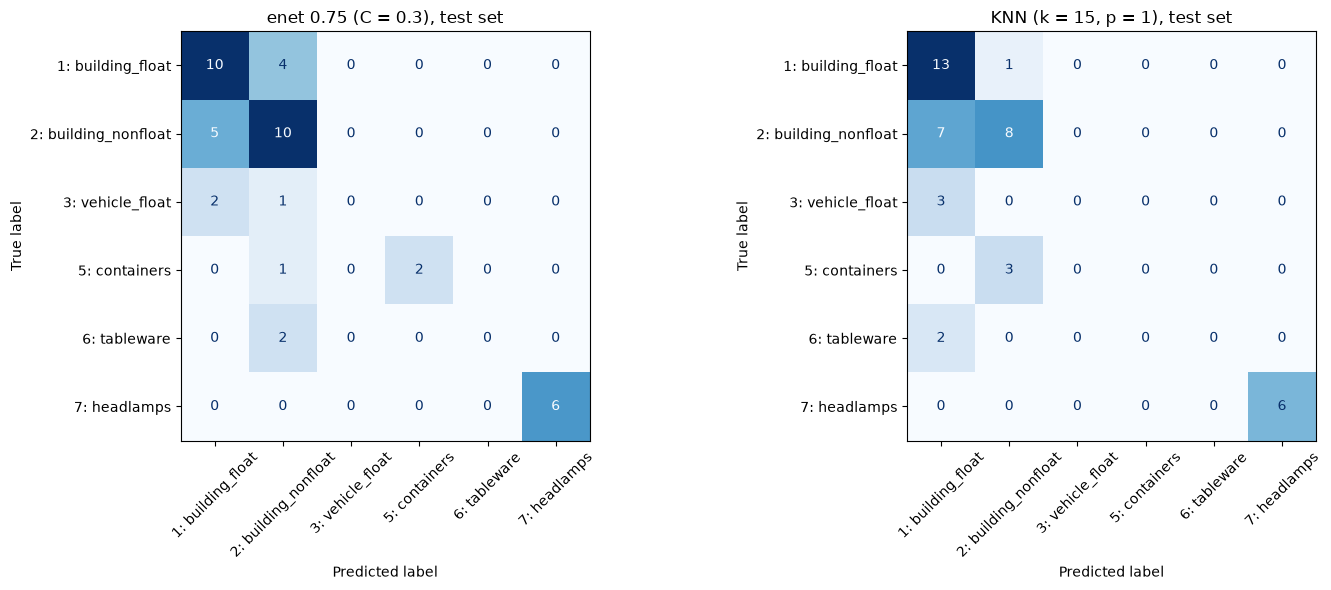

In [39]:
model_best.fit(X_train, y_train)
model_knn.fit(X_train, y_train)

test_models = [(model_best_name, model_best), (model_knn_name, model_knn)]
test_results = pd.DataFrame({
    name: {
        "test log loss": log_loss(y_test, m.predict_proba(X_test), labels=labels),
        "test accuracy": accuracy_score(y_test, m.predict(X_test)),
    }
    for name, m in test_models
}).T
display(test_results.round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (name, m) in zip(axes, test_models):
    ConfusionMatrixDisplay.from_predictions(y_test, m.predict(X_test), labels=labels, display_labels=display_names,
                                            cmap="Blues", colorbar=False, ax=ax, xticks_rotation=45)
    ax.set_title(f"{name}, test set")
plt.tight_layout()
plt.show()

#### a. Do the test results rank the models the same way as CV?

**4a: No. The test log loss is 0.8864 for the logistic model and 0.7538 for KNN, so KNN looks better, whereas in CV logistic regression was clearly better (1.09 vs 1.40). Test accuracy is 0.651 (28 of 43) for logistic and 0.628 (27 of 43) for KNN, so the accuracy ranking is also reversed compared with CV (where KNN was more accurate). The difference in accuracy is one fragment, so the test results are consistent with the two models being similar and the ranking flipping due to noise from the small test set. The CV ranking comes from 171 fragments and is more reliable.**

#### b. What can and can't we conclude from the test set?

In [40]:
print(f"A fragment with probability 0 for its true class adds {-np.log(np.finfo(float).eps):.2f} / {len(y_test)} = {-np.log(np.finfo(float).eps) / len(y_test):.3f} to the test log loss")
print("Test set class counts:")
print(y_test.value_counts().sort_index().rename(index=class_names))

A fragment with probability 0 for its true class adds 36.04 / 43 = 0.838 to the test log loss
Test set class counts:
type
building_float       14
building_nonfloat    15
vehicle_float         3
containers            3
tableware             2
headlamps             6
Name: count, dtype: int64


**4b: With so few fragments we cannot say anything reliable about per-class performance. A recall for tableware from 2 fragments, or for vehicle_float and containers from 3, can only take values like 0, 33 percent, 67 percent or 100 percent (0, 50 or 100 percent for tableware), and moving one fragment moves recall by 33 to 50 points. For example, the logistic model gets 2 of 3 containers and KNN gets 0 of 3, but that is a 2 fragment difference. What we can say is limited: both models classify all 6 headlamps correctly, both get no vehicle_float and no tableware right, and the building classes are the ones they confuse with each other, which is consistent with the CV results. We cannot conclude which model is better overall, or rank them for rare classes. A single fragment with a predicted probability of 0 for its true class adds 36.04 / 43 = 0.838 to KNN's test log loss, which is much larger than the gap between the two models (0.133), so one such fragment can change the model ranking.**